# Projek Statistika dan Probabilitas
**Analisis Waktu Pengiriman dan Ongkos Kirim pada Data Pesanan E-Commerce Olist sebagai Dasar Perancangan Data Pipeline**

Kelas 3TIC - Kelompok 2 | Konsentrasi: Data Engineer

Dataset: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

**Alur notebook:** (1) upload data -> (2) buat dataset -> (3) cek kualitas -> (4) statistika deskriptif -> (5) distribusi probabilitas -> (6) statistika inferensial -> (7) simpan hasil

## 1. Persiapan dan Upload Data
Jalankan sel di bawah, lalu pilih 2 file: `olist_orders_dataset.csv` dan `olist_order_items_dataset.csv`.

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from google.colab import files

KELAS = "3TIC"
KELOMPOK = "02"
NAMA_DATA = "PesananOlist"

uploaded = files.upload()   # pilih olist_orders_dataset.csv dan olist_order_items_dataset.csv

Saving olist_orders_dataset.csv to olist_orders_dataset.csv


In [11]:
from google.colab import files

uploaded = files.upload()

Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv


## 2. Membuat Dataset
Kedua file digabung berdasarkan `order_id`, hanya pesanan `delivered` yang dipakai, lalu dihitung `waktu_pengiriman_hari`.

In [12]:
orders = pd.read_csv("olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date"])
items = pd.read_csv("olist_order_items_dataset.csv")

total_awal = len(items)
df = items.merge(orders, on="order_id", how="inner")

# hanya pesanan yang sudah sampai (punya tanggal diterima)
df = df[(df["order_status"] == "delivered") & df["order_delivered_customer_date"].notna()].copy()

# kolom turunan: waktu pengiriman (hari)
df["waktu_pengiriman_hari"] = (
    (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
).round(2)

kolom = ["order_id", "order_item_id", "product_id", "seller_id",
         "order_purchase_timestamp", "order_delivered_customer_date",
         "price", "freight_value", "waktu_pengiriman_hari"]
df = df[kolom].reset_index(drop=True)

print("Baris awal order_items:", total_awal)
print("Baris setelah filter  :", len(df), "| Kolom:", len(df.columns))
df.head()

Baris awal order_items: 112650
Baris setelah filter  : 110189 | Kolom: 9


,order_id,order_item_id,product_id,seller_id,order_purchase_timestamp,order_delivered_customer_date,price,freight_value,waktu_pengiriman_hari
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-13 08:59:02,2017-09-20 23:43:48,58.90,13.29,7.61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 10:53:06,2017-05-12 16:04:24,239.90,19.93,16.22
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:33:31,2018-01-22 13:19:16,199.00,17.87,7.95
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-08 10:00:35,2018-08-14 13:32:39,12.99,12.79,6.15
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-04 13:57:51,2017-03-01 16:42:31,199.90,18.14,25.11


## 3. Pemeriksaan Kualitas Data

In [13]:
print("Jumlah baris:", len(df))
print("\nData kosong per kolom:")
print(df.isna().sum())
print("\nBaris kembar:", df.duplicated().sum())
print("Kembar order_id + order_item_id:", df.duplicated(["order_id", "order_item_id"]).sum())

VAR = ["price", "freight_value", "waktu_pengiriman_hari"]
NAMA = {"price": "Harga (BRL)", "freight_value": "Ongkos Kirim (BRL)", "waktu_pengiriman_hari": "Waktu Pengiriman (hari)"}
df[VAR].describe()

Jumlah baris: 110189

Data kosong per kolom:
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
order_purchase_timestamp         0
order_delivered_customer_date    0
price                            0
freight_value                    0
waktu_pengiriman_hari            0
dtype: int64

Baris kembar: 0
Kembar order_id + order_item_id: 0


,price,freight_value,waktu_pengiriman_hari
count,110189.000000,110189.000000,110189.000000
mean,119.977937,19.948869,12.472224
std,182.304615,15.698615,9.445341
min,0.850000,0.000000,0.530000
25%,39.900000,13.080000,6.740000
50%,74.900000,16.260000,10.180000
75%,134.170000,21.150000,15.540000
max,6735.000000,409.680000,209.630000


### Simpan dataset ke Excel (untuk dikumpulkan)

In [14]:
OUT_XLSX = f"{KELAS}_{KELOMPOK}_{NAMA_DATA}.xlsx"

kamus = pd.DataFrame([
 ["order_id","ID pesanan","Kualitatif","Nominal","-","Identitas"],
 ["order_item_id","Nomor urut item dalam pesanan","Kuantitatif","Diskrit","Rasio","item"],
 ["product_id","ID produk","Kualitatif","Nominal","-","Identitas"],
 ["seller_id","ID penjual","Kualitatif","Nominal","-","Identitas"],
 ["order_purchase_timestamp","Waktu pesanan dibuat","Waktu","Interval","Interval","tanggal-jam"],
 ["order_delivered_customer_date","Waktu pesanan diterima pelanggan","Waktu","Interval","Interval","tanggal-jam"],
 ["price","Harga item","Kuantitatif","Kontinu","Rasio","BRL (Real Brasil)"],
 ["freight_value","Ongkos kirim item","Kuantitatif","Kontinu","Rasio","BRL (Real Brasil)"],
 ["waktu_pengiriman_hari","Lama pengiriman = tanggal diterima - tanggal pesan","Kuantitatif","Kontinu","Rasio","hari"],
], columns=["Variabel","Keterangan","Jenis","Tipe","Skala","Satuan"])

info = pd.DataFrame({"Keterangan": [
 "Sumber: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (Olist), file olist_orders_dataset.csv & olist_order_items_dataset.csv",
 "Unit observasi: satu baris = satu item dalam pesanan",
 f"Jumlah baris awal order_items: {total_awal:,}; setelah difilter: {len(df):,}",
 "Filter: hanya order_status = delivered dan tanggal diterima tidak kosong",
 "Kolom turunan: waktu_pengiriman_hari (dihitung dari dua kolom tanggal)",
 "Missing value: tidak ada pada kolom yang dipakai setelah filter",
 "Data asli tidak diubah selain filter dan kolom turunan di atas",
]})

with pd.ExcelWriter(OUT_XLSX, engine="openpyxl", datetime_format="yyyy-mm-dd hh:mm:ss") as w:
    df.to_excel(w, sheet_name="Data", index=False)
    kamus.to_excel(w, sheet_name="Kamus Data", index=False)
    info.to_excel(w, sheet_name="Sumber & Catatan", index=False)

print("Tersimpan:", OUT_XLSX)
files.download(OUT_XLSX)

Tersimpan: 3TIC_02_PesananOlist.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Statistika Deskriptif

In [15]:
rows = []
for v in VAR:
    x = df[v]
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3 - q1
    outlier = ((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).sum()
    rows.append({"Variabel": NAMA[v], "n": len(x), "Mean": x.mean(), "Median": x.median(),
        "Modus": x.round(2).mode().iloc[0], "Std Dev": x.std(), "Varians": x.var(),
        "Min": x.min(), "Q1": q1, "Q3": q3, "Max": x.max(), "IQR": iqr,
        "Skewness": stats.skew(x), "Kurtosis": stats.kurtosis(x),
        "Jumlah Outlier (IQR)": outlier, "% Outlier": outlier/len(x)*100})
deskriptif = pd.DataFrame(rows).round(3)
os.makedirs("hasil_analisis", exist_ok=True)
deskriptif

,Variabel,n,Mean,Median,Modus,Std Dev,Varians,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis,Jumlah Outlier (IQR),% Outlier
0,Harga (BRL),110189,119.978,74.90,59.90,182.305,33234.972,0.85,39.90,134.17,6735.00,94.27,8.031,124.961,8161,7.406
1,Ongkos Kirim (BRL),110189,19.949,16.26,15.10,15.699,246.447,0.00,13.08,21.15,409.68,8.07,5.655,60.610,11811,10.719
2,Waktu Pengiriman (hari),110189,12.472,10.18,7.08,9.445,89.214,0.53,6.74,15.54,209.63,8.80,3.840,39.846,5744,5.213


In [16]:
# Fungsi untuk membuat histogram dan boxplot
def plot_deskriptif(v):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(df[v], bins=60, color="#4472C4", edgecolor="white")
    ax[0].set_title(f"Histogram {NAMA[v]}"); ax[0].set_xlabel(NAMA[v]); ax[0].set_ylabel("Frekuensi")
    ax[1].boxplot(df[v], vert=False, showfliers=True, flierprops=dict(markersize=2, alpha=.3))
    ax[1].set_title(f"Boxplot {NAMA[v]}"); ax[1].set_xlabel(NAMA[v])
    plt.tight_layout()
    plt.savefig(f"hasil_analisis/deskriptif_{v}.png", dpi=150)
    plt.show()

### Gambar 1. Histogram dan boxplot harga

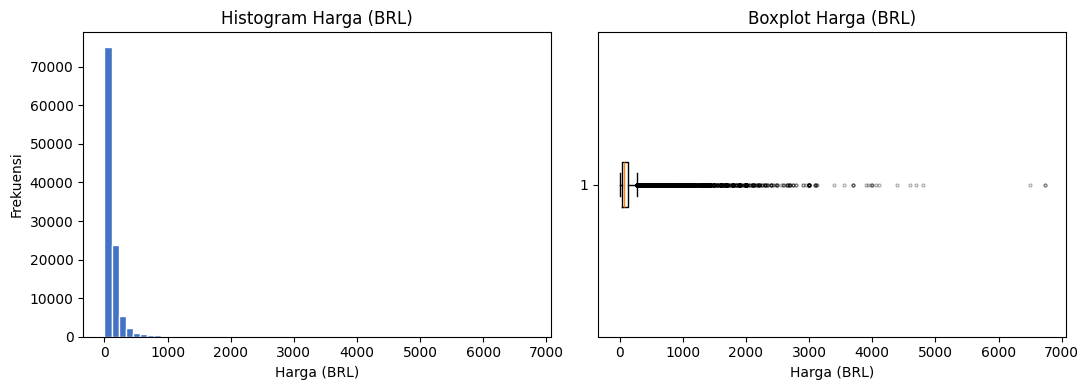

In [17]:
plot_deskriptif("price")

### Gambar 2. Histogram dan boxplot ongkos kirim

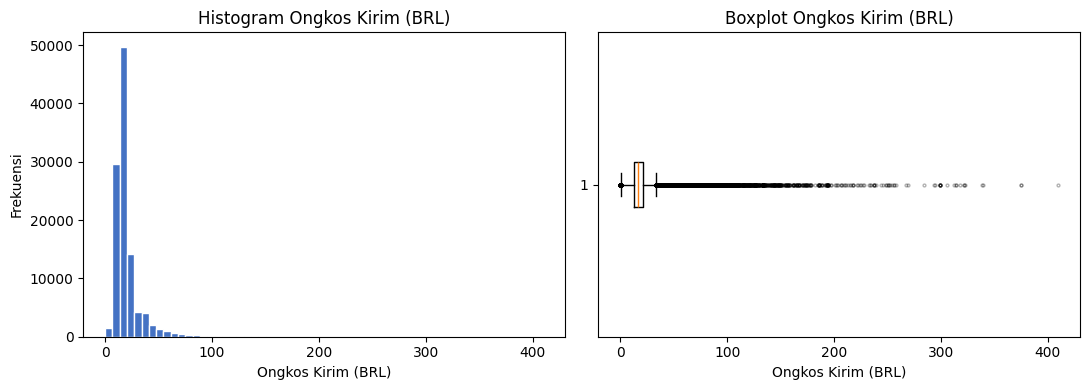

In [18]:
plot_deskriptif("freight_value")

### Gambar 3. Histogram dan boxplot waktu pengiriman

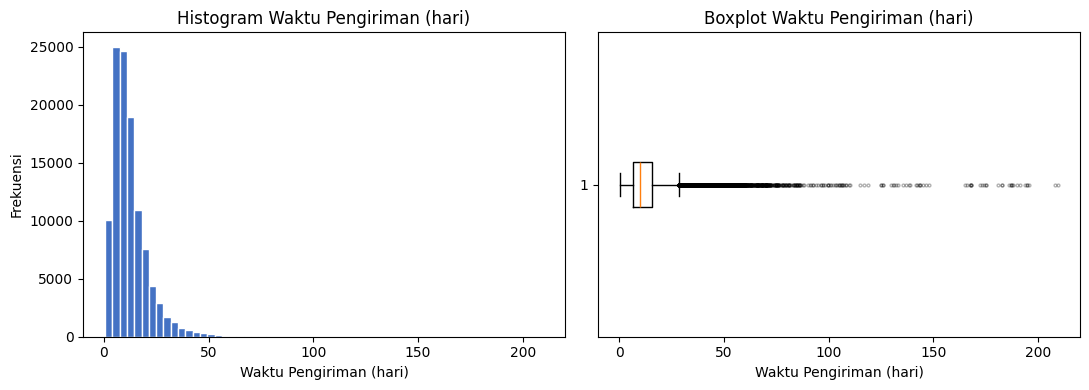

In [19]:
plot_deskriptif("waktu_pengiriman_hari")

## 5. Distribusi Probabilitas
Membandingkan Log-normal, Gamma, dan Eksponensial. Uji KS dilakukan pada sampel acak 5.000 data karena pada data besar uji KS hampir selalu menolak.

In [20]:
# Fit distribusi dan hitung AIC + uji KS
samp = df.sample(5000, random_state=42)
kandidat = {"Log-normal": stats.lognorm, "Gamma": stats.gamma, "Eksponensial": stats.expon}
params = {}
dist_rows = []
for v in VAR:
    x = df[v][df[v] > 0]
    xs = samp[v][samp[v] > 0]
    for nama, d in kandidat.items():
        par = d.fit(x, floc=0)
        params[(v, nama)] = par
        aic = 2*len(par) - 2*d.logpdf(x, *par).sum()
        ks = stats.kstest(xs, d.cdf, args=par)
        dist_rows.append({"Variabel": NAMA[v], "Distribusi": nama, "AIC": aic,
                          "KS D (sampel 5000)": ks.statistic, "KS p-value": ks.pvalue})

distribusi = pd.DataFrame(dist_rows).round(4)
distribusi["Terbaik (AIC terkecil)"] = distribusi.groupby("Variabel")["AIC"].transform(lambda s: s == s.min())
distribusi

,Variabel,Distribusi,AIC,KS D (sampel 5000),KS p-value,Terbaik (AIC terkecil)
0,Harga (BRL),Log-normal,1.245721e+06,0.0296,0.0003,True
1,Harga (BRL),Gamma,1.273279e+06,0.0945,0.0000,False
2,Harga (BRL),Eksponensial,1.275399e+06,0.0878,0.0000,False
3,Ongkos Kirim (BRL),Log-normal,8.016412e+05,0.1040,0.0000,True
4,Ongkos Kirim (BRL),Gamma,8.164853e+05,0.1468,0.0000,False
5,Ongkos Kirim (BRL),Eksponensial,8.777292e+05,0.2981,0.0000,False
6,Waktu Pengiriman (hari),Log-normal,7.344166e+05,0.0290,0.0004,True
7,Waktu Pengiriman (hari),Gamma,7.386200e+05,0.0499,0.0000,False
8,Waktu Pengiriman (hari),Eksponensial,7.765068e+05,0.1884,0.0000,False


In [21]:
# Fungsi untuk grafik pencocokan distribusi
def plot_distribusi(v):
    x = df[v][df[v] > 0]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(x.clip(upper=x.quantile(.99)), bins=60, density=True, color="#BDD7EE", edgecolor="white", label="Data")
    grid = np.linspace(x.min(), x.quantile(.99), 300)
    for nama, d in kandidat.items():
        ax.plot(grid, d.pdf(grid, *params[(v, nama)]), label=nama)
    ax.set_title(f"Pencocokan Distribusi: {NAMA[v]}"); ax.set_xlabel(NAMA[v]); ax.set_ylabel("Densitas")
    ax.legend(); plt.tight_layout()
    plt.savefig(f"hasil_analisis/distribusi_{v}.png", dpi=150)
    plt.show()

### Gambar 4. Pencocokan distribusi harga

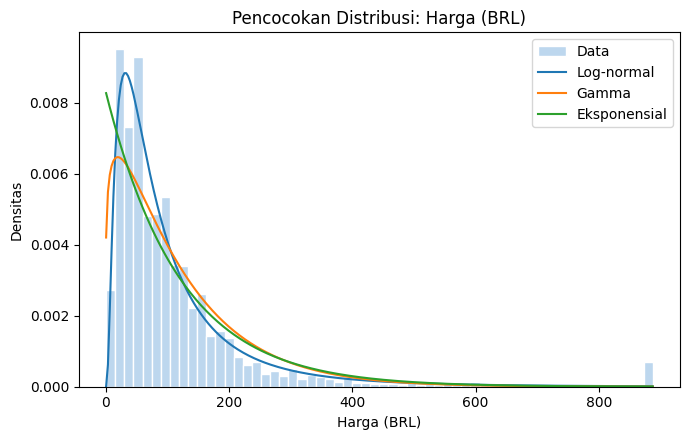

In [22]:
plot_distribusi("price")

### Gambar 5. Pencocokan distribusi ongkos kirim

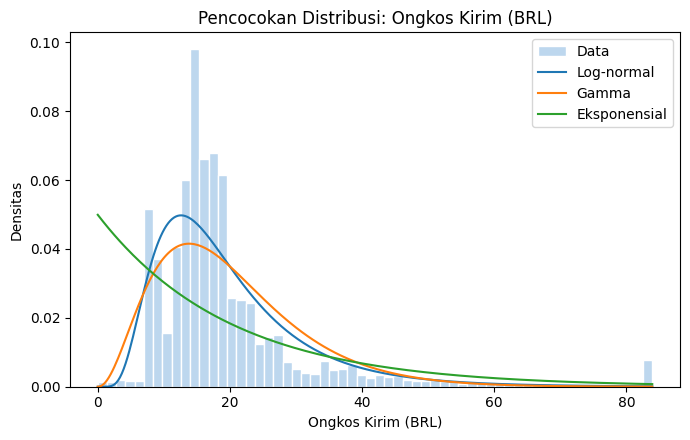

In [23]:
plot_distribusi("freight_value")

### Gambar 6. Pencocokan distribusi waktu pengiriman

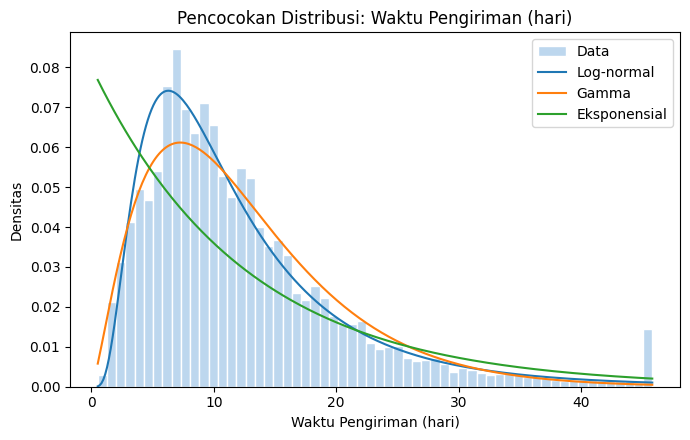

In [24]:
plot_distribusi("waktu_pengiriman_hari")

## 6. Statistika Inferensial

### 6.1 Interval kepercayaan 95% untuk rata-rata

In [25]:
ci_rows = []
for v in VAR:
    x = df[v]; se = stats.sem(x)
    lo, hi = stats.t.interval(0.95, len(x)-1, loc=x.mean(), scale=se)
    ci_rows.append({"Variabel": NAMA[v], "Mean": x.mean(), "SE": se, "CI 95% bawah": lo, "CI 95% atas": hi})
ci = pd.DataFrame(ci_rows).round(4)
ci

,Variabel,Mean,SE,CI 95% bawah,CI 95% atas
0,Harga (BRL),119.9779,0.5492,118.9015,121.0544
1,Ongkos Kirim (BRL),19.9489,0.0473,19.8562,20.0416
2,Waktu Pengiriman (hari),12.4722,0.0285,12.4165,12.5280


### 6.2 Korelasi

In [26]:
pairs = [("price", "freight_value"), ("price", "waktu_pengiriman_hari"), ("freight_value", "waktu_pengiriman_hari")]
kor_rows = []
for a, b in pairs:
    r, p = stats.pearsonr(df[a], df[b]); rs, ps = stats.spearmanr(df[a], df[b])
    kor_rows.append({"Pasangan": f"{a} - {b}", "Pearson r": r, "p Pearson": p, "Spearman rho": rs, "p Spearman": ps})
korelasi = pd.DataFrame(kor_rows).round(4)
korelasi

,Pasangan,Pearson r,p Pearson,Spearman rho,p Spearman
0,price - freight_value,0.4127,0.0,0.4339,0.0
1,price - waktu_pengiriman_hari,0.0624,0.0,0.1154,0.0
2,freight_value - waktu_pengiriman_hari,0.2147,0.0,0.4231,0.0


### Gambar 7. Heatmap korelasi Spearman

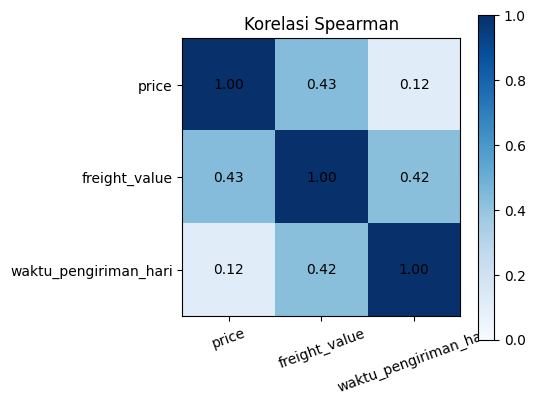

In [27]:
m = df[VAR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(VAR, rotation=20); ax.set_yticks(range(3)); ax.set_yticklabels(VAR)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{m.iloc[i,j]:.2f}", ha="center", va="center")
ax.set_title("Korelasi Spearman"); plt.colorbar(im); plt.tight_layout()
plt.savefig("hasil_analisis/korelasi_heatmap.png", dpi=150)
plt.show()

### Gambar 8. Diagram pencar ongkos kirim terhadap waktu pengiriman

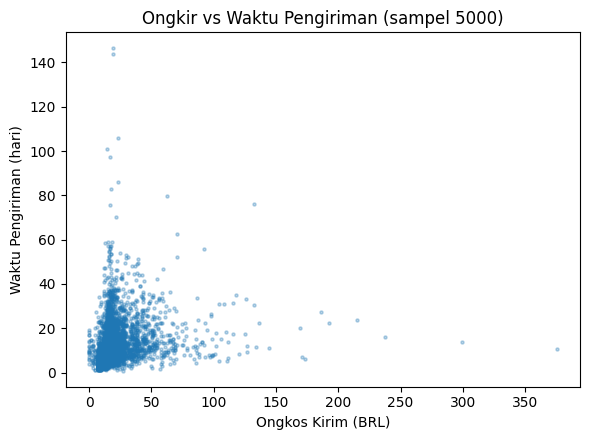

In [28]:
s2 = df.sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(s2["freight_value"], s2["waktu_pengiriman_hari"], s=5, alpha=.3)
ax.set_xlabel("Ongkos Kirim (BRL)"); ax.set_ylabel("Waktu Pengiriman (hari)")
ax.set_title("Ongkir vs Waktu Pengiriman (sampel 5000)"); plt.tight_layout()
plt.savefig("hasil_analisis/scatter_ongkir_waktu.png", dpi=150)
plt.show()

### 6.3 Uji hipotesis
**H0:** rata-rata waktu pengiriman kelompok ongkir tinggi = kelompok ongkir rendah  
**H1:** rata-rata waktu pengiriman kelompok ongkir tinggi > kelompok ongkir rendah  
Kelompok dibagi di median ongkir. Taraf signifikansi 0,05.

In [29]:
med = df["freight_value"].median()
tinggi = df.loc[df["freight_value"] > med, "waktu_pengiriman_hari"]
rendah = df.loc[df["freight_value"] <= med, "waktu_pengiriman_hari"]
t, pt = stats.ttest_ind(tinggi, rendah, equal_var=False, alternative="greater")
u, pu = stats.mannwhitneyu(tinggi, rendah, alternative="greater")
hipotesis = pd.DataFrame([
 ["Welch t-test (satu arah)", len(tinggi), len(rendah), tinggi.mean(), rendah.mean(), t, pt],
 ["Mann-Whitney U (satu arah)", len(tinggi), len(rendah), tinggi.median(), rendah.median(), u, pu]],
 columns=["Uji", "n ongkir tinggi", "n ongkir rendah", "Mean/Median tinggi", "Mean/Median rendah", "Statistik", "p-value"]).round(4)
hipotesis["Keputusan (alpha 0.05)"] = np.where(hipotesis["p-value"] < 0.05, "Tolak H0", "Gagal tolak H0")
print("Median ongkir (pembagi kelompok):", round(med, 2))
hipotesis

Median ongkir (pembagi kelompok): 16.26


,Uji,n ongkir tinggi,n ongkir rendah,Mean/Median tinggi,Mean/Median rendah,Statistik,p-value,Keputusan (alpha 0.05)
0,Welch t-test (satu arah),55028,55161,15.0211,9.9295,9.287390e+01,0.0,Tolak H0
1,Mann-Whitney U (satu arah),55028,55161,12.5900,8.0900,2.117391e+09,0.0,Tolak H0


## 7. Simpan Hasil

In [30]:
import shutil
with pd.ExcelWriter("hasil_analisis/hasil_analisis.xlsx") as w:
    deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)
    distribusi.to_excel(w, sheet_name="Distribusi", index=False)
    ci.to_excel(w, sheet_name="Interval Kepercayaan", index=False)
    korelasi.to_excel(w, sheet_name="Korelasi", index=False)
    hipotesis.to_excel(w, sheet_name="Uji Hipotesis", index=False)

shutil.make_archive("hasil_analisis", "zip", "hasil_analisis")
files.download("hasil_analisis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>